In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import yaml

# Cargar la configuración desde el YAML
# Asegúrate de que la ruta sea correcta si tu notebook está en la carpeta 'notebooks/'
ruta_config = "../config/config.yaml"

with open(ruta_config, "r", encoding="utf-8") as file:
    config = yaml.safe_load(file)
    
print("Librerías importadas y configuración cargada.")

Librerías importadas y configuración cargada.


In [4]:
# Construir la ruta al archivo Silver
ruta_silver = "../" + config["path"]["silver_dir"] + "/calidad_aire_limpio.csv"

# Cargar el DataFrame
if os.path.exists(ruta_silver):
    df_silver = pd.read_csv(ruta_silver)
    print(f"Carga exitosa desde Silver. Dimensiones: {df_silver.shape[0]} filas y {df_silver.shape[1]} columnas.")
    display(df_silver.head())
else:
    print(f"Error: No se encontró el archivo en {ruta_silver}")

Carga exitosa desde Silver. Dimensiones: 23339 filas y 12 columnas.


,country,city,aqi_value,aqi_category,co_aqi_value,co_aqi_category,ozone_aqi_value,ozone_aqi_category,no2_aqi_value,no2_aqi_category,pm2.5_aqi_value,pm2.5_aqi_category
0,Russian Federation,Praskoveya,51,Moderate,1,Good,36,Good,0,Good,51,Moderate
1,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good
2,Italy,Priolo Gargallo,66,Moderate,1,Good,39,Good,2,Good,66,Moderate
3,Poland,Przasnysz,34,Good,1,Good,34,Good,0,Good,20,Good
4,France,Punaauia,22,Good,0,Good,22,Good,0,Good,6,Good


In [3]:
print("--- VERIFICACIÓN DE CALIDAD DE DATOS ---")

# Comprobar nulos
nulos = df_silver.isnull().sum().sum()
if nulos == 0:
    print("✅ Éxito: 0 valores nulos en el dataset.")
else:
    print(f"⚠️ Atención: Aún hay {nulos} valores nulos.")
    display(df_silver.isnull().sum()[df_silver.isnull().sum() > 0])

# Comprobar duplicados
duplicados = df_silver.duplicated().sum()
if duplicados == 0:
    print("✅ Éxito: 0 filas duplicadas.")
else:
    print(f"⚠️ Atención: Se encontraron {duplicados} filas duplicadas.")

--- VERIFICACIÓN DE CALIDAD DE DATOS ---
⚠️ Atención: Aún hay 1 valores nulos.


city    1
dtype: int64

✅ Éxito: 0 filas duplicadas.


--- DISTRIBUCIÓN DE CATEGORÍAS DE CALIDAD DEL AIRE ---
aqi_category
Good                              9868
Moderate                          9189
Unhealthy                         2223
Unhealthy for Sensitive Groups    1582
Very Unhealthy                     286
Hazardous                          191
Name: count, dtype: int64


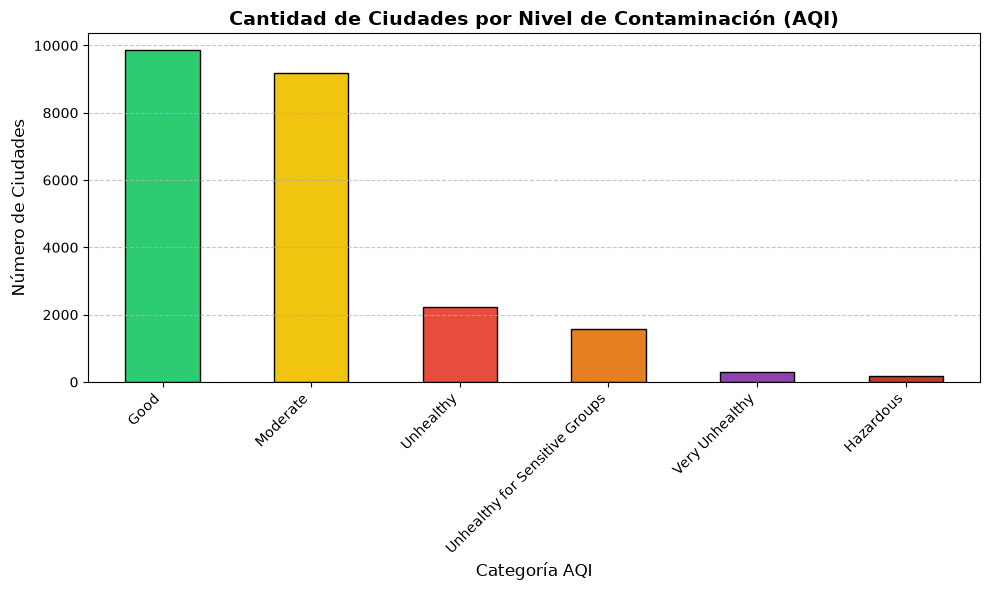

In [5]:
print("--- DISTRIBUCIÓN DE CATEGORÍAS DE CALIDAD DEL AIRE ---")

# Contar la frecuencia de cada categoría
conteo_categorias = df_silver['aqi_category'].value_counts()
print(conteo_categorias)

# Gráfico de barras
plt.figure(figsize=(10, 6))

# Asignar colores comunes para el AQI (verde para Good, rojo para Unhealthy, etc.)
colores_aqi = {'Good': '#2ecc71', 'Moderate': '#f1c40f', 'Unhealthy for Sensitive Groups': '#e67e22', 
               'Unhealthy': '#e74c3c', 'Very Unhealthy': '#8e44ad', 'Hazardous': '#c0392b'}

# Mapear los colores a las categorías presentes
colores_barras = [colores_aqi.get(cat, 'gray') for cat in conteo_categorias.index]

conteo_categorias.plot(kind='bar', color=colores_barras, edgecolor='black')

plt.title("Cantidad de Ciudades por Nivel de Contaminación (AQI)", fontsize=14, fontweight='bold')
plt.xlabel("Categoría AQI", fontsize=12)
plt.ylabel("Número de Ciudades", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

--- TOP 20 CIUDADES CON PEOR CALIDAD DE AIRE ---


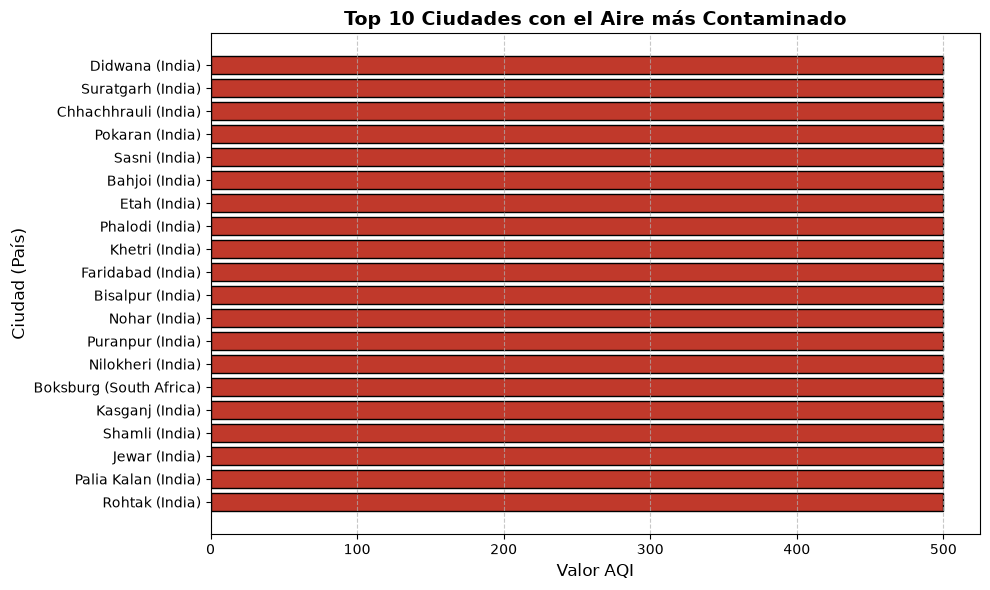

In [12]:
print("--- TOP 20 CIUDADES CON PEOR CALIDAD DE AIRE ---")

# Ordenamos de mayor a menor AQI y tomamos las 20 primeras
top_peores = df_silver.sort_values(by='aqi_value', ascending=False).head(20)

plt.figure(figsize=(10, 6))

# Creamos una etiqueta combinada "Ciudad (País)" para el gráfico
etiquetas = top_peores['city'] + " (" + top_peores['country'] + ")"

plt.barh(etiquetas, top_peores['aqi_value'], color='#c0392b', edgecolor='black')

plt.title("Top 10 Ciudades con el Aire más Contaminado", fontsize=14, fontweight='bold')
plt.xlabel("Valor AQI", fontsize=12)
plt.ylabel("Ciudad (País)", fontsize=12)
plt.gca().invert_yaxis() # Para que la peor ciudad quede arriba
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

--- PROMEDIO GLOBAL DE CONTAMINANTES ---


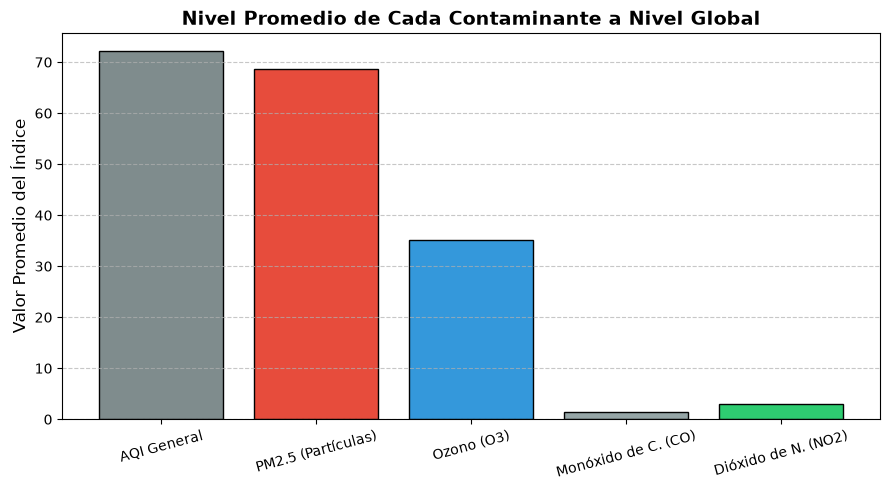

In [7]:
print("--- PROMEDIO GLOBAL DE CONTAMINANTES ---")

# Extraemos el promedio global de cada tipo de índice
promedios = {
    'AQI General': df_silver['aqi_value'].mean(),
    'PM2.5 (Partículas)': df_silver['pm2.5_aqi_value'].mean(),
    'Ozono (O3)': df_silver['ozone_aqi_value'].mean(),
    'Monóxido de C. (CO)': df_silver['co_aqi_value'].mean(),
    'Dióxido de N. (NO2)': df_silver['no2_aqi_value'].mean()
}

# Gráfico de barras simple
plt.figure(figsize=(9, 5))
plt.bar(promedios.keys(), promedios.values(), color=['#7f8c8d', '#e74c3c', '#3498db', '#95a5a6', '#2ecc71'], edgecolor='black')

plt.title("Nivel Promedio de Cada Contaminante a Nivel Global", fontsize=14, fontweight='bold')
plt.ylabel("Valor Promedio del Índice", fontsize=12)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

--- CALIDAD DEL AIRE PROMEDIO POR CONTINENTE ---


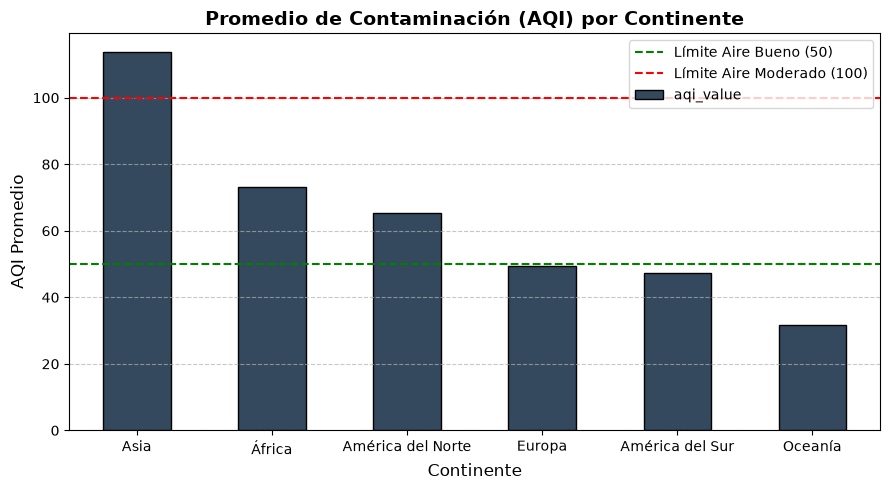

In [10]:
#%pip install pycountry-convert

import pycountry_convert as pc
import numpy as np

print("--- CALIDAD DEL AIRE PROMEDIO POR CONTINENTE ---")

# Función para convertir País a Continente
def pais_a_continente(pais):
    try:
        # Casos especiales que la libreria no suele reconocer bien
        if pais == "United States of America" or pais == "USA": return "América del Norte"
        if pais == "United Kingdom" or pais == "England" or pais == "Scotland": return "Europa"
        if pais == "Russia": return "Europa" # Simplificación
        if pais == "Republic of China (Taiwan)": return "Asia"
        if "Congo" in pais: return "África"
        
        # Conversión estándar
        codigo_pais = pc.country_name_to_country_alpha2(pais, cn_name_format="default")
        codigo_continente = pc.country_alpha2_to_continent_code(codigo_pais)
        
        diccionario_continentes = {
            'NA': 'América del Norte',
            'SA': 'América del Sur', 
            'AS': 'Asia',
            'OC': 'Oceanía',
            'EU': 'Europa',
            'AF': 'África'
        }
        return diccionario_continentes.get(codigo_continente, "Otro")
    except:
        return "Otro"

# Aplicamos la función y creamos una nueva columna temporal en el df_silver
df_silver['continente'] = df_silver['country'].apply(pais_a_continente)

# Filtramos los 'Otro' (que suelen ser islas muy pequeñas o errores)
df_continentes = df_silver[df_silver['continente'] != 'Otro']

# Agrupamos por continente y sacamos el promedio
promedio_continente = df_continentes.groupby('continente')['aqi_value'].mean().sort_values(ascending=False)

# Gráfico
plt.figure(figsize=(9, 5))
promedio_continente.plot(kind='bar', color='#34495e', edgecolor='black')

plt.title("Promedio de Contaminación (AQI) por Continente", fontsize=14, fontweight='bold')
plt.xlabel("Continente", fontsize=12)
plt.ylabel("AQI Promedio", fontsize=12)
plt.xticks(rotation=0)
plt.axhline(y=50, color='g', linestyle='--', label='Límite Aire Bueno (50)')
plt.axhline(y=100, color='r', linestyle='--', label='Límite Aire Moderado (100)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

--- COMPARATIVA: INDIA VS EL RESTO DE ASIA ---
Datos calculados:
               aqi_general    pm25
subregion                         
India               152.67  149.18
Resto de Asia        89.12   82.80


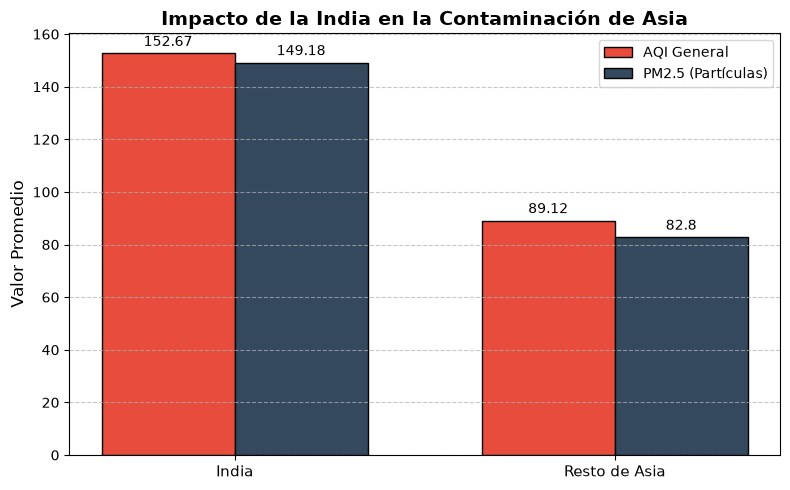

In [11]:
print("--- COMPARATIVA: INDIA VS EL RESTO DE ASIA ---")

# 1. Filtramos solo los datos del continente Asiático
df_asia = df_continentes[df_continentes['continente'] == 'Asia'].copy()

# 2. Creamos una nueva columna para separar India del resto
# Si el país es India, se llama "India". Si es otro, se llama "Resto de Asia"
df_asia['subregion'] = df_asia['country'].apply(lambda x: 'India' if x == 'India' else 'Resto de Asia')

# 3. Calculamos los promedios del AQI general y de partículas PM2.5 para ambas subregiones
promedios_asia = df_asia.groupby('subregion').agg(
    aqi_general=('aqi_value', 'mean'),
    pm25=('pm2.5_aqi_value', 'mean')
).round(2)

print("Datos calculados:")
print(promedios_asia)

# 4. Graficamos la comparativa
# Usamos un gráfico de barras agrupadas
fig, ax = plt.subplots(figsize=(8, 5))

# Posiciones de las barras
x = np.arange(len(promedios_asia.index))
ancho_barra = 0.35

# Barras para AQI General y PM2.5
barra1 = ax.bar(x - ancho_barra/2, promedios_asia['aqi_general'], ancho_barra, label='AQI General', color='#e74c3c', edgecolor='black')
barra2 = ax.bar(x + ancho_barra/2, promedios_asia['pm25'], ancho_barra, label='PM2.5 (Partículas)', color='#34495e', edgecolor='black')

# Etiquetas y diseño
ax.set_title("Impacto de la India en la Contaminación de Asia", fontsize=14, fontweight='bold')
ax.set_ylabel("Valor Promedio", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(promedios_asia.index, fontsize=11)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Añadir los números encima de las barras para mayor claridad
for barra in barra1 + barra2:
    altura = barra.get_height()
    ax.annotate(f'{altura}',
                xy=(barra.get_x() + barra.get_width() / 2, altura),
                xytext=(0, 3),  # 3 puntos de separación vertical
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

--- MATRIZ DE CORRELACIÓN DE CONTAMINANTES ---


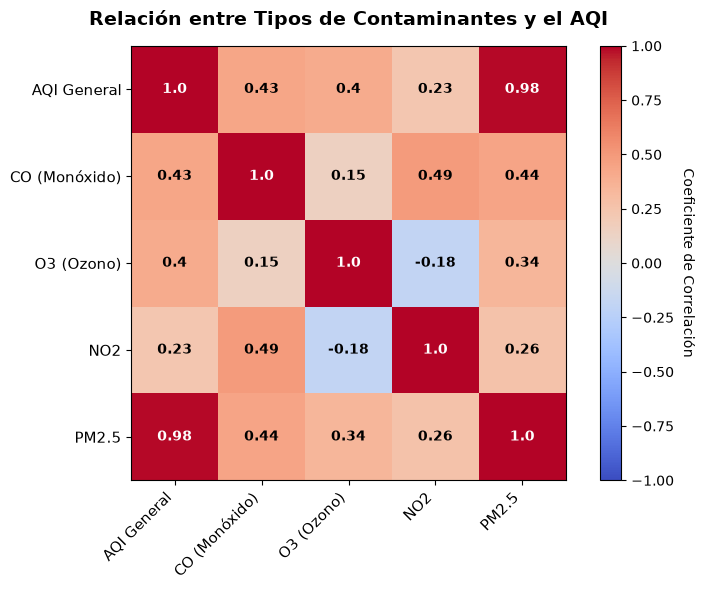


Observación clave: La correlación entre el AQI General y las partículas PM2.5 es de 0.98.
Si el valor es cercano a 1, significa que el PM2.5 es el principal culpable de disparar las alertas ambientales.


In [13]:
print("--- MATRIZ DE CORRELACIÓN DE CONTAMINANTES ---")

# 1. Seleccionar solo las columnas numéricas de los contaminantes
columnas_numericas = ['aqi_value', 'co_aqi_value', 'ozone_aqi_value', 'no2_aqi_value', 'pm2.5_aqi_value']
df_corr = df_silver[columnas_numericas].copy()

# Renombramos las columnas temporalmente para que el gráfico se lea mejor
df_corr.columns = ['AQI General', 'CO (Monóxido)', 'O3 (Ozono)', 'NO2', 'PM2.5']

# 2. Calcular la matriz de correlación (método de Pearson)
matriz_corr = df_corr.corr()

# 3. Construir el Heatmap usando solo Matplotlib
fig, ax = plt.subplots(figsize=(8, 6))

# imshow dibuja la cuadrícula de colores (de -1 a 1) usando la paleta 'coolwarm'
cax = ax.imshow(matriz_corr, cmap='coolwarm', vmin=-1, vmax=1)

# Añadimos la barra de leyenda a la derecha
cbar = fig.colorbar(cax)
cbar.set_label('Coeficiente de Correlación', rotation=270, labelpad=15)

# Configuramos las etiquetas de los ejes X y Y
etiquetas = matriz_corr.columns
ax.set_xticks(np.arange(len(etiquetas)))
ax.set_yticks(np.arange(len(etiquetas)))
ax.set_xticklabels(etiquetas, rotation=45, ha='right', fontsize=11)
ax.set_yticklabels(etiquetas, fontsize=11)

# 4. Inyectar los valores numéricos dentro de los cuadros
for i in range(len(etiquetas)):
    for j in range(len(etiquetas)):
        # Extraemos el valor y lo redondeamos a 2 decimales
        valor = round(matriz_corr.iloc[i, j], 2)
        
        # Cambiamos el color del texto a blanco si el fondo es muy oscuro (para que se lea bien)
        color_texto = "white" if abs(valor) > 0.6 else "black"
        
        # Dibujamos el texto en la coordenada exacta
        ax.text(j, i, valor, ha="center", va="center", color=color_texto, fontweight='bold')

ax.set_title("Relación entre Tipos de Contaminantes y el AQI", fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

# Imprimir conclusión automatizada
correlacion_pm25_aqi = round(matriz_corr.loc['AQI General', 'PM2.5'], 2)
print(f"\nObservación clave: La correlación entre el AQI General y las partículas PM2.5 es de {correlacion_pm25_aqi}.")
print("Si el valor es cercano a 1, significa que el PM2.5 es el principal culpable de disparar las alertas ambientales.")